# **Playing Card** Dataset exploration
Initial dataset exploration

In [1]:
DATASET_FOLDER = 'dataset/PlayingCards'

## Dataset directory structure

The `dataset/PlayingCards` folder has the following structure:
```text
PlayingCards/
│
├── test/
│   ├── images/
|   │   └── *.jpg
│   └── labels/
|       └── *.txt
│
├── train/
│   ├── images/
|   │   └── *.jpg
│   └── labels/
|       └── *.txt
│
├── val/
│   ├── images/
|   │   └── *.jpg
│   └── labels/
|       └── *.txt
│
├── data.yaml
├── README.roboflow.txt
└── README.dataset.txt
```

In [2]:
### Count number of files (per type) in each first level subfolder

from pathlib import Path
from collections import defaultdict

# Construct path
base_path = Path(DATASET_FOLDER)

# loop over all first level folder
for folder in sorted(p for p in base_path.iterdir() if p.is_dir()):
    counts = defaultdict(int)

    # count file based on their type
    for file in folder.iterdir():
        if file.is_file():
            counts[file.suffix.lower() or "<no_ext>"] += 1

    # print folder by folder
    print(f"{folder.name}/")
    for ext, count in sorted(counts.items()):
        print(f"  {ext}: {count}")

test/
train/
valid/


In [14]:
FOLDERS = ["train", "valid", "test"]

## Annotation files

Annotation files `*.txt` have the following structure:
```text
23 0.7226311673694983 0.27059236035616396 0.04927384134309047 0.07215680113146812
2 0.6584777607017711 0.26240715563389966 0.0414613413430903 0.07211134933607007
12 0.576619233370453 0.27677366178221974 0.03988066000954511 0.07053975897699045
12 0.45545494740608755 0.5385509782353901 0.03988066000954493 0.07053975897699054
```

## Categories

### Construct information map

In [6]:
cat dataset/PlayingCards/data.yaml

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 52
names: ['10C', '10D', '10H', '10S', '2C', '2D', '2H', '2S', '3C', '3D', '3H', '3S', '4C', '4D', '4H', '4S', '5C', '5D', '5H', '5S', '6C', '6D', '6H', '6S', '7C', '7D', '7H', '7S', '8C', '8D', '8H', '8S', '9C', '9D', '9H', '9S', 'AC', 'AD', 'AH', 'AS', 'JC', 'JD', 'JH', 'JS', 'KC', 'KD', 'KH', 'KS', 'QC', 'QD', 'QH', 'QS']

roboflow:
  workspace: augmented-startups
  project: playing-cards-ow27d
  version: 4
  license: Public Domain
  url: https://universe.roboflow.com/augmented-startups/playing-cards-ow27d/dataset/4

In [12]:
CATEGORY_MAP = {}

import yaml
with open(DATASET_FOLDER + "/data.yaml", "r", encoding="utf-8") as stream:
    try:
        data_file = yaml.safe_load(stream)

        categories = data_file["names"]

        for cat_idx, cat_name in enumerate(categories):
            CATEGORY_MAP[cat_idx] = {
                "name": cat_name, 
                "count_test": 0,
                "count_train": 0,
                "count_val": 0
            }
    except yaml.YAMLError as exc:
        print(exc)

print(CATEGORY_MAP)

{0: {'name': '10C', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 1: {'name': '10D', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 2: {'name': '10H', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 3: {'name': '10S', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 4: {'name': '2C', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 5: {'name': '2D', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 6: {'name': '2H', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 7: {'name': '2S', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 8: {'name': '3C', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 9: {'name': '3D', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 10: {'name': '3H', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 11: {'name': '3S', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 12: {'name': '4C', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 13: {'name': '4D', 'count_test': 0, 'count_train': 0, 'count_val': 0}, 14: {'name'

In [23]:
labels_folder = [f"{DATASET_FOLDER}/{f}/labels" for f in FOLDERS]

IMAGE_MAP = {}

# in this loop do two things:
# 1) count number of annotations per category (train, val, test)
# 2) count number of images, with number of annotation per image

for folder in labels_folder:
    for file in Path(folder).iterdir():
        if file.is_file() and file.suffix.lower() == ".txt":
            with open(file, "r", encoding="utf-8") as f:
                
                # Create new image entry if not exists
                if file.stem not in IMAGE_MAP:
                    IMAGE_MAP[file.stem] = {
                        "num_annotations": 0,
                        "categories": set()
                    }

                for line in f:
                    cat_idx = int(line.split()[0])

                    # update image map
                    IMAGE_MAP[file.stem]["num_annotations"] += 1
                    IMAGE_MAP[file.stem]["categories"].add(cat_idx)

                    # update category map count
                    if cat_idx in CATEGORY_MAP:
                        if "train" in folder:
                            CATEGORY_MAP[cat_idx]["count_train"] += 1
                        elif "val" in folder:
                            CATEGORY_MAP[cat_idx]["count_val"] += 1
                        elif "test" in folder:
                            CATEGORY_MAP[cat_idx]["count_test"] += 1

print(CATEGORY_MAP)

{0: {'name': '10C', 'count_test': 154, 'count_train': 4794, 'count_val': 344}, 1: {'name': '10D', 'count_test': 148, 'count_train': 4725, 'count_val': 322}, 2: {'name': '10H', 'count_test': 108, 'count_train': 5085, 'count_val': 296}, 3: {'name': '10S', 'count_test': 172, 'count_train': 5094, 'count_val': 306}, 4: {'name': '2C', 'count_test': 172, 'count_train': 4815, 'count_val': 288}, 5: {'name': '2D', 'count_test': 136, 'count_train': 4788, 'count_val': 330}, 6: {'name': '2H', 'count_test': 170, 'count_train': 4548, 'count_val': 366}, 7: {'name': '2S', 'count_test': 168, 'count_train': 4866, 'count_val': 274}, 8: {'name': '3C', 'count_test': 146, 'count_train': 5091, 'count_val': 352}, 9: {'name': '3D', 'count_test': 150, 'count_train': 4581, 'count_val': 290}, 10: {'name': '3H', 'count_test': 176, 'count_train': 4644, 'count_val': 336}, 11: {'name': '3S', 'count_test': 186, 'count_train': 4875, 'count_val': 284}, 12: {'name': '4C', 'count_test': 134, 'count_train': 5229, 'count_val

### Info print

In [19]:
map_sorted = dict(
    sorted(
        CATEGORY_MAP.items(), 
        key=lambda item: item[1]["count_train"], 
        reverse=True
    )
)

print("\n--- CATEGORIES SORTED BY NUMBER OF ANNOTATIONS ---")
for i, (cat_id, cat_info) in enumerate(map_sorted.items()):
    print(f"{(i+1):<2}) {cat_info['name']:<3} ({cat_id:<2}): {cat_info['count_train']:<5} train, {cat_info['count_val']:<5} val, {cat_info['count_test']:<5} test")


--- CATEGORIES SORTED BY NUMBER OF ANNOTATIONS ---
1 ) QS  (51): 3536  train, 161   val, 80    test
2 ) JC  (40): 3518  train, 137   val, 69    test
3 ) 4D  (13): 3512  train, 119   val, 102   test
4 ) 5C  (16): 3498  train, 177   val, 94    test
5 ) 4C  (12): 3486  train, 173   val, 67    test
6 ) 4H  (14): 3450  train, 146   val, 86    test
7 ) KS  (47): 3438  train, 118   val, 65    test
8 ) 9D  (33): 3410  train, 140   val, 65    test
9 ) AD  (37): 3406  train, 146   val, 85    test
10) KD  (45): 3402  train, 144   val, 71    test
11) 10S (3 ): 3396  train, 153   val, 86    test
12) 3C  (8 ): 3394  train, 176   val, 73    test
13) 10H (2 ): 3390  train, 148   val, 54    test
14) 7S  (27): 3388  train, 148   val, 90    test
15) QC  (48): 3378  train, 142   val, 75    test
16) 5D  (17): 3368  train, 182   val, 68    test
17) 6S  (23): 3352  train, 129   val, 71    test
18) 7H  (26): 3352  train, 160   val, 75    test
19) 5S  (19): 3348  train, 157   val, 79    test
20) AS  (39): 334

In [22]:
avg_bb_per_cat = sum(cat["count_train"] for cat in CATEGORY_MAP.values()) / len(CATEGORY_MAP)
print(f"\nAverage number of bounding boxes (train) per category: {avg_bb_per_cat:.2f}")


Average number of bounding boxes (train) per category: 3261.12


## Images

### Info print

In [24]:
image_sorted = dict(
    sorted(
        IMAGE_MAP.items(),
        key= lambda item: item[1]["num_annotations"],
        reverse=True
    )
)

In [34]:
Kt = 5
print(f"\n--- {Kt} IMAGES WITH MOST BOUNDING BOXES ---")
for i, (img_id, info) in enumerate(image_sorted.items()):
    if i >= Kt:
        break
    print(f"{i+1}) {img_id}.jpg: {info["num_annotations"]} bbs, categories {info["categories"]}")

Kl = 5
print(f"\n--- {Kl} IMAGES WITH LEAST BOUNDING BOXES ---")
for i, (img_id, info) in enumerate(reversed(list(image_sorted.items()))):
    if i >= Kl:
        break
    print(f"{i+1}) {img_id}.jpg: {info['num_annotations']} bbs, categories {info['categories']}")


--- 5 IMAGES WITH MOST BOUNDING BOXES ---
1) 973989946_jpg.rf.ec07d7dd6408b89fb77516eb475d8591.jpg: 4 bbs, categories {8, 9, 36}
2) 688586158_jpg.rf.428114ea517ba41f050ad40e1b3dfb3d.jpg: 4 bbs, categories {26, 43, 50}
3) 730313286_jpg.rf.6d2eed27c43d0b2ff0bdd0887df42a9a.jpg: 4 bbs, categories {1, 18, 39}
4) 956519816_jpg.rf.5f60d5c05a08fe4b7fb8e7ab29c4b603.jpg: 4 bbs, categories {48, 10, 47}
5) 637853938_jpg.rf.bfcf05527eca674670de04c8d1b0f182.jpg: 4 bbs, categories {32, 36, 46}

--- 5 IMAGES WITH LEAST BOUNDING BOXES ---
1) 110041158_jpg.rf.d901b07d837df234adfb6fed7aa5591f.jpg: 3 bbs, categories {35, 45, 23}
2) 859416359_jpg.rf.c93398f1ef54c8283005750db2eb6e6f.jpg: 3 bbs, categories {9, 42, 38}
3) 294167512_jpg.rf.7d7d9a6825bf9cdd7c20518a2ccf8cc1.jpg: 3 bbs, categories {41, 13, 45}
4) 543385550_jpg.rf.ffea4f6c59d0522e8344b8ae507ab858.jpg: 3 bbs, categories {9, 2, 27}
5) 645376742_jpg.rf.9c74bdc94418714ac1f5d5ab4a4b541a.jpg: 3 bbs, categories {16, 21, 45}


## General information

In [26]:
bb_count_total = sum(i["num_annotations"] for i in IMAGE_MAP.values())

In [27]:
print("\n--- GENERAL STATISTICS ---")
print("Categories:", len(CATEGORY_MAP))
print("Images:", len(IMAGE_MAP))
print("Bounding boxes:", bb_count_total)


--- GENERAL STATISTICS ---
Categories: 52
Images: 24233
Bounding boxes: 96909


In [31]:
print(f"Average bounding boxes per category: {avg_bb_per_cat:.2f}")

avg_bb_per_img = bb_count_total/ len(IMAGE_MAP)
print(f"Average bounding boxes per image: {avg_bb_per_img:.6f}")

Average bounding boxes per category: 3261.12
Average bounding boxes per image: 3.999051


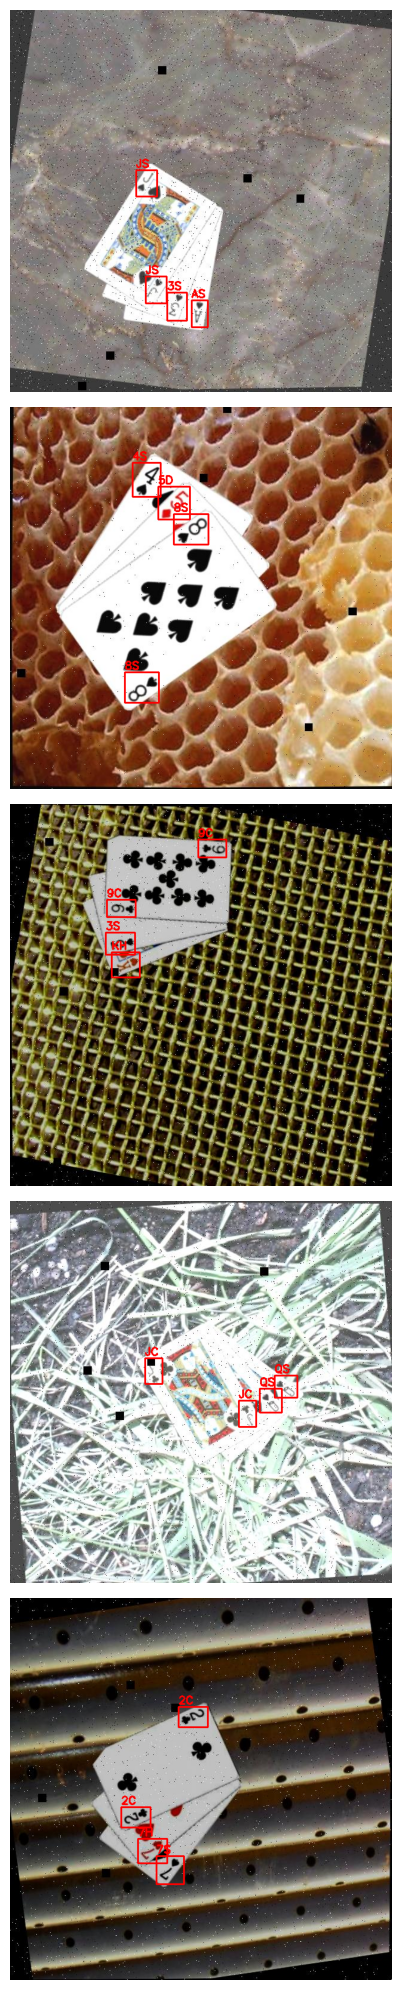

In [33]:
# plot some random images with their bounding boxes and category names

import os
import random
import cv2
import matplotlib.pyplot as plt

# path base
root = f"{DATASET_FOLDER}/train"
img_dir = os.path.join(root, "images")
label_dir = os.path.join(root, "labels")

class_names = {k: v["name"] for k, v in CATEGORY_MAP.items()}

def load_labels(label_path, img_w, img_h):
    boxes = []
    if not os.path.exists(label_path):
        return boxes

    with open(label_path, "r") as f:
        for line in f:
            cls, x, y, w, h = map(float, line.strip().split())

            x1 = int((x - w/2) * img_w)
            y1 = int((y - h/2) * img_h)
            x2 = int((x + w/2) * img_w)
            y2 = int((y + h/2) * img_h)

            boxes.append((int(cls), x1, y1, x2, y2))
    return boxes

def plot_random_samples(n=5):
    images = [f for f in os.listdir(img_dir) if f.endswith(".jpg")]
    samples = random.sample(images, n)

    plt.figure(figsize=(12, 4*n))

    for i, img_name in enumerate(samples):
        img_path = os.path.join(img_dir, img_name)
        label_path = os.path.join(label_dir, img_name.replace(".jpg", ".txt"))

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        boxes = load_labels(label_path, w, h)

        for cls, x1, y1, x2, y2 in boxes:
            color = (255, 0, 0)
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            cv2.putText(img, class_names[cls],
                        (x1, max(0, y1 - 5)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.6, color, 2)

        plt.subplot(n, 1, i+1)
        plt.imshow(img)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

plot_random_samples(5)